# Assignment Module 2: Aircraft Classification

The goal of this assignment is to implement a neural network that classifies images of 100 aircraft model variants from the [Fine-Grained Visual Classification of Aircraft (**FGVC-Aircraft**) dataset](https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/). The assignment is divided into two parts: first, you will be asked to implement your own neural network for image classification from scratch; then, you will fine-tune a pretrained network provided by PyTorch.

![](https:///raw.githubusercontent.com/CVLAB-Unibo/ipcv-assignment-2/master/fgvc_aircraft_variants.svg)

## Part 0 — Environment and configuration

The environment is detected automatically (Colab / Kaggle / SLURM cluster / local) and sets `DATA_ROOT`, `DEVICE` and the random seed.

**Kaggle notes**
- Turn on `Settings → Internet: On` (otherwise the dataset download fails; enabling GPU + internet for the first time requires phone verification of the account).
- Use an interactive **Edit** session for debugging (like Colab, it can be recycled when the browser disconnects). For long unattended runs use **Save & Run All (Commit)**: the whole notebook is executed on Kaggle's servers independently of your browser. A single commit run is capped at about 12 hours.
- Checkpoints and results are written to `/kaggle/working/` and are kept with the version output.

**Cluster (SLURM) notes**
- `$HOME` has a 400 MB quota, so the data and checkpoints must go to scratch space. The environment variables `IPCV_DATA_ROOT` and `IPCV_CKPT_DIR` override the defaults on any platform (see `cluster/run_notebook.sbatch`).

In [1]:
import os, sys, math, time, json, random, collections
from pathlib import Path
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms
from torchvision.datasets import FGVCAircraft
import matplotlib.pyplot as plt
from IPython.display import display   # also available when the notebook is run as a plain script

IN_COLAB  = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input") or "KAGGLE_KERNEL_RUN_TYPE" in os.environ
IN_SLURM  = "SLURM_JOB_ID" in os.environ

# Where the dataset lives. IPCV_DATA_ROOT (if set) always wins. On the DISI cluster $HOME has a
# 400 MB quota, so there it must point to /scratch.hpc/... (see cluster/run_notebook.sbatch).
if os.environ.get("IPCV_DATA_ROOT"):
    DATA_ROOT = Path(os.environ["IPCV_DATA_ROOT"])
elif IN_COLAB:
    DATA_ROOT = Path("/content/data")
elif IN_KAGGLE:
    DATA_ROOT = Path("/kaggle/working/data")
else:
    DATA_ROOT = Path.home() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)

DEVICE = (torch.device("cuda") if torch.cuda.is_available()
          else torch.device("mps") if torch.backends.mps.is_available()
          else torch.device("cpu"))

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()
torch.backends.cudnn.benchmark = True

PLATFORM = ("Colab" if IN_COLAB else "Kaggle" if IN_KAGGLE
            else "SLURM cluster" if IN_SLURM else "local")
print(f"torch {torch.__version__} | tv {torchvision.__version__}")
print(f"platform={PLATFORM} | device={DEVICE} | data_root={DATA_ROOT}")
if IN_KAGGLE:
    print("Kaggle reminder: make sure Settings -> Internet is ON, otherwise the dataset download fails.")

torch 2.11.0+cu128 | tv 0.26.0+cu128
platform=SLURM cluster | device=cuda | data_root=/scratch.hpc/luyao.ma/ipcv_a2/data


## Dataset

Download and acces the dataset through its official [PyTorch `FGVCAircraft` class](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.FGVCAircraft.html) (by setting its constructor argument `annotation_level` to `'variant'`).

### Dataset notes

FGVC-Aircraft: 100 aircraft *variant* classes, ~3333 images each in train/val/test, roughly balanced. Every image has a ~20 px copyright banner at the bottom, which is cropped before resizing. `train` is used for training, `val` for model selection / early stopping / tuning, and `test` only for reporting the final numbers. The first download is ~2.75 GB (Oxford VGG website; if it fails, download the tarball manually and put it in `DATA_ROOT`).

In [2]:
# --- Robust FGVC-Aircraft download (the Oxford VGG site sometimes returns 403 / times out) ---
# torchvision expects <DATA_ROOT>/fgvc-aircraft-2013b/ ; if the tarball already exists it skips the download and only extracts.
import urllib.request, shutil, ssl

_TAR = DATA_ROOT / "fgvc-aircraft-2013b.tar.gz"
_URL = "https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/archives/fgvc-aircraft-2013b.tar.gz"

if (DATA_ROOT / "fgvc-aircraft-2013b").exists():
    print("Already extracted, skipping")
elif _TAR.exists() and _TAR.stat().st_size > 2_000_000_000:
    print(f"Tarball in place ({_TAR.stat().st_size/1e9:.2f} GB), letting torchvision extract it")
else:
    ctx = ssl.create_default_context(); ctx.check_hostname = False; ctx.verify_mode = ssl.CERT_NONE
    for attempt in range(1, 6):
        try:
            print(f"Download attempt {attempt}/5 ...")
            req = urllib.request.Request(_URL, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=120, context=ctx) as r, open(_TAR, "wb") as f:
                shutil.copyfileobj(r, f, length=1 << 20)
            print(f"Done: {_TAR.stat().st_size/1e9:.2f} GB")
            break
        except Exception as e:
            print("  failed:", e)
    else:
        print("\nAutomatic download failed. Manual fallback: upload fgvc-aircraft-2013b.tar.gz to\n "
              f"{_TAR}\nthen re-run this cell and the next one (torchvision extracts it automatically).")

Already extracted, skipping


In [3]:
NUM_CLASSES = 100

def load_raw(split):
    return FGVCAircraft(root=str(DATA_ROOT), split=split,
                        annotation_level="variant", download=True, transform=None)

raw_train, raw_val, raw_test = load_raw("train"), load_raw("val"), load_raw("test")
print(f"train {len(raw_train)} | val {len(raw_val)} | test {len(raw_test)}")
print(f"#classes = {len(raw_train.classes)}  e.g. {raw_train.classes[:4]}")
assert len(raw_train.classes) == NUM_CLASSES

train 3334 | val 3333 | test 3333
#classes = 100  e.g. ['707-320', '727-200', '737-200', '737-300']


In [4]:
class CropBottomBanner:
    """Remove the ~20 px copyright banner at the bottom of every FGVC-Aircraft image"""
    def __init__(self, px=20): self.px = px
    def __call__(self, img):
        w, h = img.size
        return img.crop((0, 0, w, h - self.px))

IMG_SIZE  = 128
RESIZE_TO = int(round(IMG_SIZE * 1.14))   # resize first, then center-crop, to keep the aspect ratio

def compute_mean_std(base, n=1500):
    tf = transforms.Compose([CropBottomBanner(20),
                             transforms.Resize(RESIZE_TO),
                             transforms.CenterCrop(IMG_SIZE),
                             transforms.ToTensor()])
    idx = np.random.default_rng(SEED).choice(len(base), min(n, len(base)), replace=False)
    mean = torch.zeros(3); sq = torch.zeros(3)
    for i in idx:
        x = tf(base[i][0]); mean += x.mean((1, 2)); sq += (x**2).mean((1, 2))
    mean /= len(idx); std = (sq/len(idx) - mean**2).sqrt()
    return mean.tolist(), std.tolist()

FGVC_MEAN, FGVC_STD = compute_mean_std(raw_train)
print("mean", [round(v, 4) for v in FGVC_MEAN], "std", [round(v, 4) for v in FGVC_STD])

mean [0.4906, 0.5203, 0.5437] std [0.22, 0.213, 0.2427]


In [5]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def build_train_tf(img_size=IMG_SIZE, mean=None, std=None,
                   augment=True, rrc=True, hflip=True, jitter=True):
    mean = mean or FGVC_MEAN; std = std or FGVC_STD
    steps = [CropBottomBanner(20)]
    if augment and rrc:
        steps.append(transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0), ratio=(0.8, 1.25)))
    else:
        steps += [transforms.Resize(int(round(img_size*1.14))), transforms.CenterCrop(img_size)]
    if augment and hflip:  steps.append(transforms.RandomHorizontalFlip())
    if augment and jitter: steps.append(transforms.ColorJitter(0.2, 0.2, 0.2))
    steps += [transforms.ToTensor(), transforms.Normalize(mean, std)]
    return transforms.Compose(steps)

def build_eval_tf(img_size=IMG_SIZE, mean=None, std=None):
    mean = mean or FGVC_MEAN; std = std or FGVC_STD
    return transforms.Compose([CropBottomBanner(20),
                               transforms.Resize(int(round(img_size*1.14))),
                               transforms.CenterCrop(img_size),
                               transforms.ToTensor(), transforms.Normalize(mean, std)])

In [6]:
class Transformed(Dataset):
    def __init__(self, base, tf): self.base, self.tf = base, tf
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        img, y = self.base[i]; return self.tf(img), y

def make_loaders(img_size=IMG_SIZE, batch_size=128, mean=None, std=None,
                 augment=True, rrc=True, hflip=True, jitter=True, num_workers=2):
    ttf = build_train_tf(img_size, mean, std, augment, rrc, hflip, jitter)
    etf = build_eval_tf(img_size, mean, std)
    common = dict(num_workers=num_workers, pin_memory=(DEVICE.type == "cuda"))
    return (DataLoader(Transformed(raw_train, ttf), batch_size, shuffle=True,  drop_last=True, **common),
            DataLoader(Transformed(raw_val,   etf), batch_size, shuffle=False,                 **common),
            DataLoader(Transformed(raw_test,  etf), batch_size, shuffle=False,                 **common))

## EDA

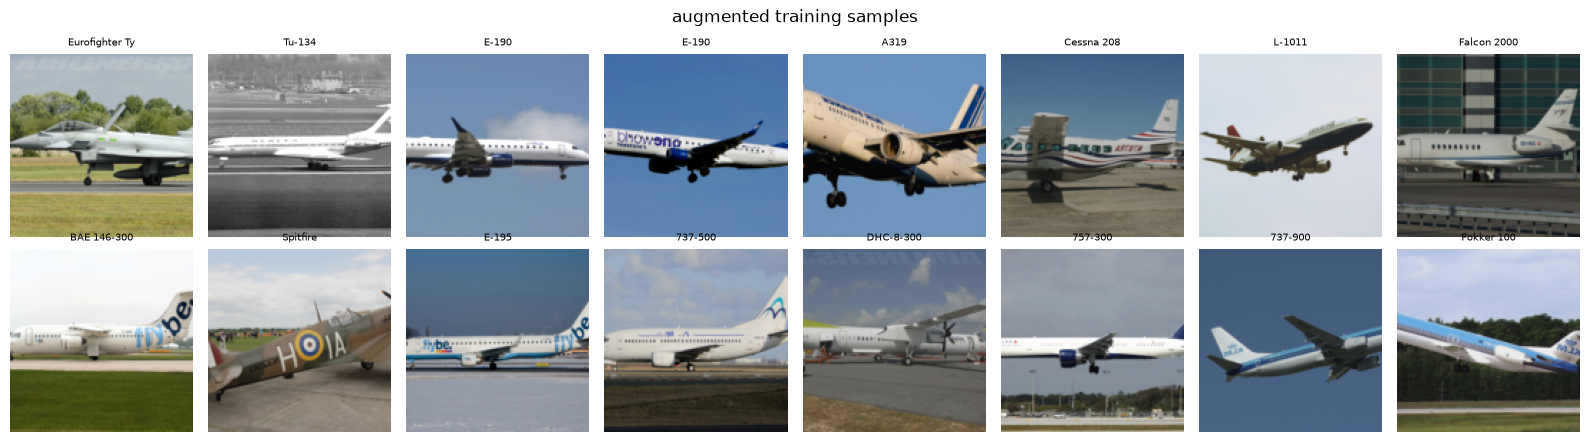

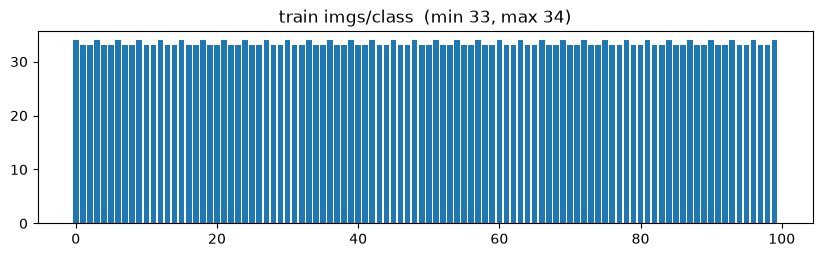

raw W 775-1600 | raw H 465-1079


In [7]:
def denorm(x, mean=None, std=None):
    mean = torch.tensor(mean or FGVC_MEAN).view(3, 1, 1)
    std  = torch.tensor(std  or FGVC_STD ).view(3, 1, 1)
    return (x*std + mean).clamp(0, 1)

# 1) grid of augmented training samples
tl, _, _ = make_loaders(batch_size=16, num_workers=0)
xb, yb = next(iter(tl))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, im, y in zip(axes.flat, xb, yb):
    ax.imshow(denorm(im).permute(1, 2, 0).numpy()); ax.axis("off")
    ax.set_title(raw_train.classes[y][:14], fontsize=7)
plt.suptitle("augmented training samples"); plt.tight_layout(); plt.show()

# 2) class distribution
_lbl = getattr(raw_train, "_labels", None)
lbl = np.array(_lbl if _lbl is not None else [y for _, y in raw_train])
cnt = np.bincount(lbl, minlength=NUM_CLASSES)
plt.figure(figsize=(10, 2.5)); plt.bar(range(NUM_CLASSES), cnt)
plt.title(f"train imgs/class  (min {cnt.min()}, max {cnt.max()})"); plt.show()

# 3) raw image sizes
s = np.array([raw_train[i][0].size for i in np.random.default_rng(0).integers(0, len(raw_train), 200)])
print(f"raw W {s[:,0].min()}-{s[:,0].max()} | raw H {s[:,1].min()}-{s[:,1].max()}")

## Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `FGVCAircraft`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~50%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~50% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

### 1.1  Architecture: ResNet-lite (configurable)

A stride-2 `stem` followed by 4 stages; the first block of every stage downsamples with stride 2: `128 → 64 → 32 → 16 → 8 → 4`. The final `512×4×4` feature map goes through **global average pooling** → Dropout → `Linear(512, 100)`.

- Each `BasicBlock` is two `Conv3×3 →(BN)→ activation` layers; with `use_residual=True` a shortcut is added, using a `1×1 conv` projection wherever the size/channels change (the standard ResNet recipe).
- Convolutions use Kaiming (`fan_out`) initialisation; BN weights are initialised to 1 and biases to 0.
- **Every design choice is one switch of `NetConfig`**, so an ablation only changes the config: `use_bn` · `use_residual` · `activation` · `global_pool` (avg/flatten) · `dropout` · `stage_channels` (capacity).

In [8]:
from dataclasses import dataclass, asdict

ACT = {"relu": nn.ReLU, "gelu": nn.GELU, "leaky_relu": lambda: nn.LeakyReLU(0.1)}

@dataclass
class NetConfig:
    num_classes:      int   = 100
    stem_channels:    int   = 32
    stage_channels:   tuple = (64, 128, 256, 512)
    blocks_per_stage: int   = 2
    use_bn:           bool  = True         # ablation
    use_residual:     bool  = True         # ablation
    activation:       str   = "relu"       # relu | gelu | leaky_relu   ablation
    global_pool:      str   = "avg"        # "avg" | "flatten"          ablation
    dropout:          float = 0.3          # ablation
    in_size:          int   = 128

def _norm(c, use_bn):
    return nn.BatchNorm2d(c) if use_bn else nn.Identity()

class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, cfg):
        super().__init__()
        act = ACT[cfg.activation]
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=not cfg.use_bn)
        self.n1, self.act1 = _norm(cout, cfg.use_bn), act()
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=not cfg.use_bn)
        self.n2, self.act2 = _norm(cout, cfg.use_bn), act()
        self.use_residual = cfg.use_residual
        if cfg.use_residual and (stride != 1 or cin != cout):
            self.short = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=not cfg.use_bn),
                                       _norm(cout, cfg.use_bn))
        else:
            self.short = nn.Identity()

    def forward(self, x):
        out = self.act1(self.n1(self.conv1(x)))
        out = self.n2(self.conv2(out))
        if self.use_residual:
            out = out + self.short(x)
        return self.act2(out)

class AircraftNet(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        act = ACT[cfg.activation]
        self.stem = nn.Sequential(
            nn.Conv2d(3, cfg.stem_channels, 3, 2, 1, bias=not cfg.use_bn),
            _norm(cfg.stem_channels, cfg.use_bn), act())
        blocks, cin = [], cfg.stem_channels
        for cout in cfg.stage_channels:
            for bi in range(cfg.blocks_per_stage):
                blocks.append(BasicBlock(cin, cout, 2 if bi == 0 else 1, cfg))
                cin = cout
        self.stages = nn.Sequential(*blocks)
        feat = cfg.stage_channels[-1]
        if cfg.global_pool == "avg":
            self.pool, head_in = nn.AdaptiveAvgPool2d(1), feat
        elif cfg.global_pool == "flatten":
            r = cfg.in_size // 2 // (2 ** len(cfg.stage_channels))
            self.pool, head_in = nn.Identity(), feat * r * r
        else:
            raise ValueError(cfg.global_pool)
        self.drop = nn.Dropout(cfg.dropout)
        self.fc   = nn.Linear(head_in, cfg.num_classes)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stem(x); x = self.stages(x); x = self.pool(x)
        x = torch.flatten(x, 1); x = self.drop(x)
        return self.fc(x)

def build_model(cfg=None):
    return AircraftNet(cfg or NetConfig())

_cfg = NetConfig(); _m = build_model(_cfg)
print(f"params: {sum(p.numel() for p in _m.parameters())/1e6:.2f}M | "
      f"out: {tuple(_m(torch.randn(2, 3, _cfg.in_size, _cfg.in_size)).shape)}")
del _cfg, _m

params: 11.20M | out: (2, 100)


### 1.2  Training framework (shared by Part 1 and Part 2)

- `TrainConfig` collects all training hyper-parameters; `build_optimizer` supports SGD / AdamW and `build_scheduler` supports `cosine` (linear warm-up + cosine annealing) and `constant` (flat LR, used for the "no schedule" ablation).
- `train_loop`: mixed precision (AMP) on CUDA; every epoch it records `lr / train_loss / train_top1 / val_loss / val_top1 / val_top5` and keeps the best weights according to **val top-1**.
- `run_experiment(name, net_cfg, train_cfg)`: builds loaders → model → trains → evaluates the best weights on **test** (top-1 + top-5), registers the result in the global `RESULTS`, stores a checkpoint in `CKPT_DIR` and dumps `results.json`. On start-up `RESULTS` is re-loaded from `results.json` if it exists, so tables and plots can be rebuilt after a kernel restart without retraining. An optional `model_builder` argument lets Part 2 train an externally built model (ResNet-18) with the same machinery.
- Strict splits: `train` trains, `val` selects, `test` is only used for the final report.

In [9]:
# Checkpoint / results directory:
#   IPCV_CKPT_DIR (env var) -> explicit override (cluster: a directory under /scratch.hpc)
#   Colab                   -> Google Drive (survives disconnects)
#   Kaggle                  -> /kaggle/working (kept with the version output, survives a background commit run)
#   otherwise               -> ./ckpts
if os.environ.get("IPCV_CKPT_DIR"):
    CKPT_DIR = Path(os.environ["IPCV_CKPT_DIR"])
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT_DIR = Path("/content/drive/MyDrive/ipcv_assignment2/ckpts")
elif IN_KAGGLE:
    CKPT_DIR = Path("/kaggle/working/ckpts")
else:
    CKPT_DIR = Path("ckpts")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_JSON = CKPT_DIR.parent / "results.json"
print("CKPT_DIR    :", CKPT_DIR)
print("RESULTS_JSON:", RESULTS_JSON)

CKPT_DIR    : /scratch.hpc/luyao.ma/ipcv_a2/ckpts
RESULTS_JSON: /scratch.hpc/luyao.ma/ipcv_a2/results.json


In [10]:
from dataclasses import dataclass, field, asdict, replace

@dataclass
class TrainConfig:
    epochs:          int   = 80
    batch_size:      int   = 128
    optimizer:       str   = "sgd"       # sgd | adamw
    lr:              float = 0.1         # use ~3e-4 with adamw
    momentum:        float = 0.9
    weight_decay:    float = 5e-4
    nesterov:        bool  = True
    scheduler:       str   = "cosine"    # cosine | constant   <- ablation
    warmup_epochs:   int   = 5
    label_smoothing: float = 0.0         # Part 2B tuning
    no_wd_on_bn:     bool  = False       # Part 2B tuning: no weight decay on BN parameters / biases
    grad_clip:       float = 0.0
    amp:             bool  = True        # only effective on CUDA
    img_size:        int   = 128
    mean: tuple = None                   # None -> FGVC statistics computed on train; Part 2 passes IMAGENET_MEAN
    std:  tuple = None
    augment: bool = True
    rrc:     bool = True
    hflip:   bool = True
    jitter:  bool = True
    num_workers: int = int(os.environ.get("IPCV_NUM_WORKERS", 2))   # set IPCV_NUM_WORKERS on machines with more CPU cores
    seed: int = 42


def build_optimizer(model, cfg: TrainConfig):
    if cfg.no_wd_on_bn:
        # 1-D parameters = BN gamma/beta + all biases: no weight decay
        # (as in the torchvision 2021 re-training recipe presented in lecture P2L6)
        decay, no_decay = [], []
        for n, p in model.named_parameters():
            if not p.requires_grad:
                continue
            (no_decay if p.ndim <= 1 else decay).append(p)
        params = [{"params": decay, "weight_decay": cfg.weight_decay},
                  {"params": no_decay, "weight_decay": 0.0}]
    else:
        params = model.parameters()
    if cfg.optimizer == "sgd":
        return torch.optim.SGD(params, lr=cfg.lr, momentum=cfg.momentum,
                               weight_decay=cfg.weight_decay, nesterov=cfg.nesterov)
    if cfg.optimizer == "adamw":
        return torch.optim.AdamW(params, lr=cfg.lr, weight_decay=cfg.weight_decay)
    raise ValueError(cfg.optimizer)


def build_scheduler(opt, cfg: TrainConfig):
    """Stepped once per epoch. constant = flat LR (used by the "no schedule" ablation)."""
    if cfg.scheduler == "constant":
        return torch.optim.lr_scheduler.LambdaLR(opt, lambda _: 1.0)
    warm = torch.optim.lr_scheduler.LinearLR(
        opt, start_factor=1e-2, total_iters=max(1, cfg.warmup_epochs))
    cos = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=max(1, cfg.epochs - cfg.warmup_epochs))
    return torch.optim.lr_scheduler.SequentialLR(
        opt, [warm, cos], milestones=[max(1, cfg.warmup_epochs)])

In [11]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot = 0; loss_sum = 0.0; c1 = 0; c5 = 0
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True); y = y.to(DEVICE, non_blocking=True)
        out = model(x)
        loss_sum += criterion(out, y).item() * x.size(0); tot += x.size(0)
        top5 = out.topk(5, dim=1).indices
        c1 += (top5[:, 0] == y).sum().item()
        c5 += (top5 == y[:, None]).any(dim=1).sum().item()
    return loss_sum / tot, 100 * c1 / tot, 100 * c5 / tot


def train_loop(model, train_loader, val_loader, cfg: TrainConfig, verbose=True):
    crit  = nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)
    opt   = build_optimizer(model, cfg)
    sched = build_scheduler(opt, cfg)
    use_amp = cfg.amp and DEVICE.type == "cuda"
    scaler  = torch.amp.GradScaler("cuda", enabled=use_amp)

    keys = ["lr", "train_loss", "train_top1", "val_loss", "val_top1", "val_top5"]
    hist = {k: [] for k in keys}
    best_val = -1.0; best_state = None

    for ep in range(1, cfg.epochs + 1):
        model.train()
        t0 = time.time(); seen = 0; run_loss = 0.0; run_c1 = 0
        for x, y in train_loader:
            x = x.to(DEVICE, non_blocking=True); y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward()
            if cfg.grad_clip > 0:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(opt); scaler.update()
            run_loss += loss.item() * x.size(0); seen += x.size(0)
            run_c1   += (out.argmax(1) == y).sum().item()
        sched.step()

        tr_loss = run_loss / seen; tr_top1 = 100 * run_c1 / seen
        va_loss, va_top1, va_top5 = evaluate(model, val_loader, crit)
        lr_now = opt.param_groups[0]["lr"]
        for k, v in zip(keys, [lr_now, tr_loss, tr_top1, va_loss, va_top1, va_top5]):
            hist[k].append(v)
        if va_top1 > best_val:
            best_val = va_top1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"ep {ep:3d}/{cfg.epochs} | lr {lr_now:.4f} | "
                  f"train {tr_loss:.3f}/{tr_top1:5.1f}% | "
                  f"val {va_loss:.3f}/{va_top1:5.1f}% (top5 {va_top5:4.1f}%) | "
                  f"{time.time() - t0:4.1f}s")
    return hist, best_state, best_val

In [12]:
RESULTS = {}
# Re-load results written by earlier sessions (e.g. after a kernel restart), so that tables and plots
# can be rebuilt without re-training.
if RESULTS_JSON.exists():
    try:
        RESULTS.update(json.loads(RESULTS_JSON.read_text())["full"])
        print(f"Re-loaded {len(RESULTS)} earlier results from {RESULTS_JSON}")
    except Exception as e:
        print("Could not re-load", RESULTS_JSON, "->", e)

def _dump_results():
    slim = {k: {kk: vv for kk, vv in v.items() if kk != "history"} for k, v in RESULTS.items()}
    RESULTS_JSON.write_text(json.dumps({"slim": slim, "full": RESULTS}, indent=2, default=str))

def run_experiment(name, net_cfg=None, train_cfg=None, save_ckpt=True, verbose=True,
                   model_builder=None):
    """model_builder: optional custom model factory (Part 2 passes the ResNet-18 here); when given it
    bypasses build_model(net_cfg) and net_cfg is only kept for the record.
    With IPCV_SKIP_DONE=1 an experiment that is already stored in results.json is not re-trained
    (lets a long one-shot job be resumed after a crash / time-out)."""
    train_cfg = train_cfg or TrainConfig()
    if os.environ.get("IPCV_SKIP_DONE") == "1" and RESULTS.get(name, {}).get("history"):
        print(f"[{name}] already finished (found in results.json) -> skipped")
        return RESULTS[name]
    seed_everything(train_cfg.seed)
    tl, vl, testl = make_loaders(
        img_size=train_cfg.img_size, batch_size=train_cfg.batch_size,
        mean=train_cfg.mean, std=train_cfg.std,
        augment=train_cfg.augment, rrc=train_cfg.rrc,
        hflip=train_cfg.hflip, jitter=train_cfg.jitter, num_workers=train_cfg.num_workers)
    if model_builder is not None:
        model = model_builder().to(DEVICE)
        net_cfg_dict = {"builder": getattr(model_builder, "__name__", str(model_builder))}
    else:
        net_cfg = replace(net_cfg or NetConfig(), in_size=train_cfg.img_size)
        model = build_model(net_cfg).to(DEVICE)
        net_cfg_dict = asdict(net_cfg)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"=== {name} === {n_params/1e6:.2f}M params | img {train_cfg.img_size} | "
          f"{train_cfg.optimizer} lr{train_cfg.lr} wd{train_cfg.weight_decay} | "
          f"sched={train_cfg.scheduler} | {train_cfg.epochs} ep")
    t0 = time.time()
    hist, best_state, best_val = train_loop(model, tl, vl, train_cfg, verbose=verbose)
    model.load_state_dict(best_state)
    _, te1, te5 = evaluate(model, testl, nn.CrossEntropyLoss())
    rec = dict(name=name, test_top1=te1, test_top5=te5, best_val_top1=best_val,
               n_params=int(n_params), minutes=(time.time() - t0) / 60,
               history=hist, net_cfg=net_cfg_dict, train_cfg=asdict(train_cfg))
    RESULTS[name] = rec
    if save_ckpt:
        torch.save({"model": best_state, "net_cfg": rec["net_cfg"],
                    "train_cfg": asdict(train_cfg), "test_top1": te1},
                   CKPT_DIR / f"{name}.pt")
    _dump_results()
    print(f"[{name}]  test top1 {te1:.2f}%  top5 {te5:.2f}%  |  best val {best_val:.2f}%  "
          f"|  {rec['minutes']:.1f} min")
    return rec


def plot_history(hist_or_name, title=""):
    h = RESULTS[hist_or_name]["history"] if isinstance(hist_or_name, str) else hist_or_name
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    ax[0].plot(ep, h["train_loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="val")
    ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["train_top1"], label="train"); ax[1].plot(ep, h["val_top1"], label="val")
    ax[1].set_title("top-1 (%)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    ax[2].plot(ep, h["lr"]); ax[2].set_title("lr"); ax[2].set_xlabel("epoch")
    fig.suptitle(title or (hist_or_name if isinstance(hist_or_name, str) else ""))
    plt.tight_layout(); plt.show()


def results_table(names=None):
    import pandas as pd
    names = names or list(RESULTS)
    rows = [dict(experiment=n,
                 test_top1=round(RESULTS[n]["test_top1"], 2),
                 test_top5=round(RESULTS[n]["test_top5"], 2),
                 val_top1=round(RESULTS[n]["best_val_top1"], 2),
                 params_M=round(RESULTS[n]["n_params"] / 1e6, 2),
                 min=round(RESULTS[n]["minutes"], 1)) for n in names]
    return pd.DataFrame(rows).set_index("experiment")

### 1.3  Training the best model and hyper-parameter exploration

**Strategy**: first run a baseline and inspect the real training curves (train vs val gap, epoch of saturation, oscillation), and only then decide where to search, instead of running a blind grid search.

**Baseline** = default `NetConfig()` + `TrainConfig()`: ResNet-lite with ~11M parameters · 128 px · full augmentation · BN + residuals + dropout 0.3 · SGD lr 0.1 with 5-epoch warm-up + cosine · wd 5e-4 · batch 128 · 80 epochs.

Candidates considered afterwards (to be chosen after seeing the baseline): model capacity `(48,96,192,384)` / `blocks_per_stage=1`; learning rate {0.05, 0.1, 0.2}; an AdamW (lr 3e-4) control; 80 → 120 epochs; dropout {0.2, 0.3, 0.5}; resolution 160. Fallbacks: MixUp/CutMix, RandAugment, higher resolution, TTA.

In [13]:
# --- Baseline: default configuration ---
base_net   = NetConfig()
base_train = TrainConfig(epochs=80)
run_experiment("p1_baseline", net_cfg=base_net, train_cfg=base_train)

=== p1_baseline === 11.20M params | img 128 | sgd lr0.1 wd0.0005 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.757/  0.7% | val 4.619/  1.2% (top5  6.5%) | 60.6s


ep   2/80 | lr 0.0406 | train 4.720/  1.6% | val 4.751/  2.1% (top5  8.1%) | 27.1s


ep   3/80 | lr 0.0604 | train 4.641/  2.0% | val 4.644/  2.7% (top5 10.1%) | 27.2s


ep   4/80 | lr 0.0802 | train 4.533/  2.9% | val 4.524/  3.4% (top5 13.5%) | 27.4s


...

ep  78/80 | lr 0.0002 | train 0.039/ 99.4% | val 3.298/ 33.8% (top5 64.5%) | 27.4s


ep  79/80 | lr 0.0000 | train 0.042/ 99.1% | val 3.301/ 33.8% (top5 64.6%) | 27.6s


ep  80/80 | lr 0.0000 | train 0.041/ 99.3% | val 3.300/ 33.8% (top5 64.6%) | 27.6s


[p1_baseline]  test top1 34.32%  top5 63.85%  |  best val 34.29%  |  38.0 min


{'name': 'p1_baseline',
 'test_top1': 34.32343234323432,
 'test_top5': 63.846384638463846,
 'best_val_top1': 34.293429342934296,
 'n_params': 11202948,
 'minutes': 37.973800834019976,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.0634459910307

In [14]:
results_table()

,test_top1,test_top5,val_top1,params_M,min
experiment,,,,,
p1_baseline,34.32,63.85,34.29,11.2,38.0


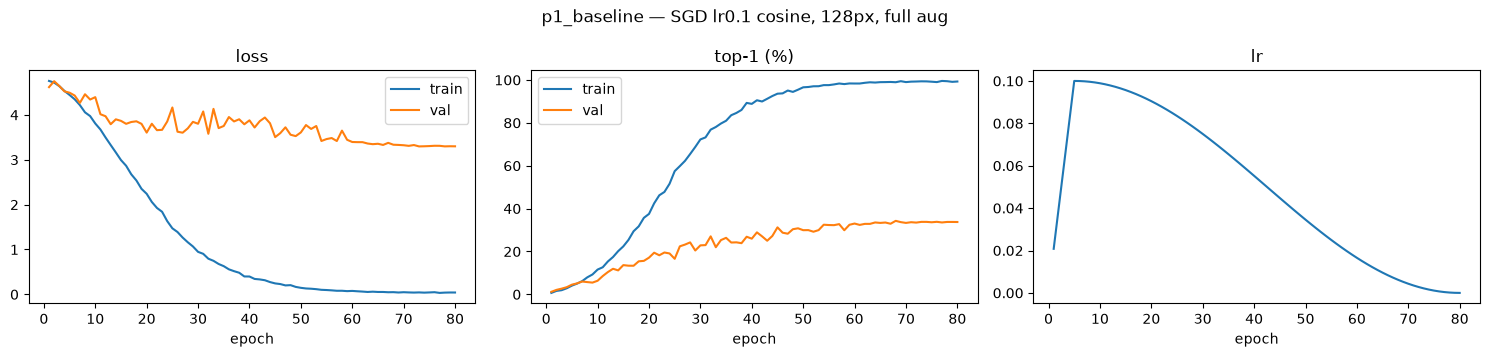

In [15]:
plot_history("p1_baseline", title="p1_baseline — SGD lr0.1 cosine, 128px, full aug")

#### Baseline analysis

- **Final result**: test top-1 **34.32%**, test top-5 **63.85%**, best val top-1 **34.29%** (epoch 68); 11.2M parameters; 38.0 min of training.
- **Severe overfitting**: `train_top1` passes 98.5% at epoch 62 and ends at 99.3%, while `val_top1` stays in a narrow 32.4–34.3% band from epoch 60 on — a final train/val gap of **65.5 points**.
- **Val loss decreases only slowly** (3.40 at epoch 60, 3.30 at the end) while `val_top1` is flat (33.5–33.8% in the last five epochs): the model becomes more confident on the samples it already gets right, but does not learn to get more new samples right.
- **Not a matter of training length**: the last ~20 epochs are already flat. The bottleneck is that the **capacity (11.2M parameters) is far too large for 3334 training images**, and the current regularisation (BN + augmentation + dropout 0.3 + wd 5e-4) cannot hold it back.
- The ≈50% test top-1 reference is still **~15.7 points** away.

**Conclusion**: the planned probes (smaller capacity / smaller capacity + stronger regularisation / AdamW) go in the right direction; what matters is which one narrows the train/val gap under the same 35 epochs.

#### Probe experiments (35 epochs, quick direction finding)

The baseline (11.2M parameters) already shows a large overfitting gap by epoch 30 (train 72% / val 23%), and val oscillates. 80 epochs are expensive, so short 35-epoch runs are used first to find the direction; the winner is then trained for the full 80 epochs as `p1_best`.

- `p1_probe_smallcap`: reduced capacity `(48,96,192,384)`, everything else as in the baseline
- `p1_probe_smallcap_reg`: reduced capacity + weight decay ×2 + dropout 0.5
- `p1_probe_adamw`: baseline capacity with AdamW (lr 3e-4, wd 1e-2)

In [16]:
# --- Probe 1: smaller model capacity ---
run_experiment(
    "p1_probe_smallcap",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384)),
    train_cfg=TrainConfig(epochs=35),
)

=== p1_probe_smallcap === 6.32M params | img 128 | sgd lr0.1 wd0.0005 | sched=cosine | 35 ep


ep   1/35 | lr 0.0208 | train 4.745/  0.9% | val 4.632/  1.0% (top5  5.3%) | 36.3s


ep   2/35 | lr 0.0406 | train 4.735/  1.2% | val 5.329/  1.4% (top5  6.5%) | 27.5s


ep   3/35 | lr 0.0604 | train 4.670/  2.0% | val 5.002/  2.0% (top5  8.9%) | 27.3s


ep   4/35 | lr 0.0802 | train 4.567/  2.5% | val 4.582/  3.4% (top5 13.1%) | 27.5s


...

ep  33/35 | lr 0.0011 | train 0.608/ 84.5% | val 3.029/ 29.8% (top5 61.8%) | 27.5s


ep  34/35 | lr 0.0003 | train 0.591/ 84.9% | val 2.995/ 30.4% (top5 62.6%) | 27.5s


ep  35/35 | lr 0.0000 | train 0.556/ 85.9% | val 2.992/ 30.2% (top5 62.3%) | 27.4s


[p1_probe_smallcap]  test top1 30.51%  top5 62.02%  |  best val 30.42%  |  16.5 min


{'name': 'p1_probe_smallcap',
 'test_top1': 30.513051305130514,
 'test_top5': 62.016201620162015,
 'best_val_top1': 30.423042304230425,
 'n_params': 6317348,
 'minutes': 16.49568259716034,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09972609476841367,
   0.09890738003669028,
   0.09755282581475767,
   0.09567727288213003,
   0.09330127018922194,
   0.09045084971874737,
   0.0871572412738697,
   0.0834565303179429,
   0.07938926261462365,
   0.07499999999999998,
   0.07033683215379001,
   0.06545084971874737,
   0.06039558454088796,
   0.05522642316338268,
   0.05000000000000001,
   0.04477357683661733,
   0.03960441545911203,
   0.03454915028125263,
   0.02966316784621,
   0.025000000000000012,
   0.02061073738537635,
   0.016543469682057107,
   0.012842758726130301,
   0.009549150281252635,
   0.006698729810778067,
   0.004322727117869953,
   0.002447174185242324,
   0.0010926199633097158,
   0.00027390523158633,
   0.0],
  'train_loss': [4.

In [17]:
# --- Probe 2: smaller capacity + stronger regularisation ---
run_experiment(
    "p1_probe_smallcap_reg",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384), dropout=0.5),
    train_cfg=TrainConfig(epochs=35, weight_decay=1e-3),
)

=== p1_probe_smallcap_reg === 6.32M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 35 ep


ep   1/35 | lr 0.0208 | train 4.801/  1.3% | val 4.635/  1.1% (top5  5.5%) | 27.9s


ep   2/35 | lr 0.0406 | train 4.804/  0.8% | val 5.040/  1.2% (top5  6.5%) | 28.1s


ep   3/35 | lr 0.0604 | train 4.736/  1.7% | val 5.559/  1.7% (top5  7.3%) | 27.1s


ep   4/35 | lr 0.0802 | train 4.629/  2.1% | val 4.611/  2.7% (top5 11.3%) | 27.6s


...

ep  33/35 | lr 0.0011 | train 1.063/ 70.0% | val 2.709/ 30.1% (top5 64.4%) | 27.1s


ep  34/35 | lr 0.0003 | train 1.042/ 71.0% | val 2.693/ 30.6% (top5 65.3%) | 27.5s


ep  35/35 | lr 0.0000 | train 1.005/ 72.1% | val 2.701/ 30.1% (top5 65.3%) | 27.3s


[p1_probe_smallcap_reg]  test top1 30.66%  top5 64.93%  |  best val 30.63%  |  16.4 min


{'name': 'p1_probe_smallcap_reg',
 'test_top1': 30.663066306630665,
 'test_top5': 64.92649264926493,
 'best_val_top1': 30.633063306330634,
 'n_params': 6317348,
 'minutes': 16.35554793278376,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09972609476841367,
   0.09890738003669028,
   0.09755282581475767,
   0.09567727288213003,
   0.09330127018922194,
   0.09045084971874737,
   0.0871572412738697,
   0.0834565303179429,
   0.07938926261462365,
   0.07499999999999998,
   0.07033683215379001,
   0.06545084971874737,
   0.06039558454088796,
   0.05522642316338268,
   0.05000000000000001,
   0.04477357683661733,
   0.03960441545911203,
   0.03454915028125263,
   0.02966316784621,
   0.025000000000000012,
   0.02061073738537635,
   0.016543469682057107,
   0.012842758726130301,
   0.009549150281252635,
   0.006698729810778067,
   0.004322727117869953,
   0.002447174185242324,
   0.0010926199633097158,
   0.00027390523158633,
   0.0],
  'train_loss': 

In [18]:
# --- Probe 3: AdamW control (baseline capacity) ---
run_experiment(
    "p1_probe_adamw",
    net_cfg=NetConfig(),
    train_cfg=TrainConfig(epochs=35, optimizer="adamw", lr=3e-4, weight_decay=1e-2),
)

=== p1_probe_adamw === 11.20M params | img 128 | adamw lr0.0003 wd0.01 | sched=cosine | 35 ep


ep   1/35 | lr 0.0001 | train 4.794/  0.8% | val 4.662/  1.1% (top5  5.4%) | 27.8s


ep   2/35 | lr 0.0001 | train 4.687/  1.8% | val 4.567/  2.4% (top5  9.4%) | 27.8s


ep   3/35 | lr 0.0002 | train 4.559/  2.8% | val 4.496/  3.0% (top5 12.0%) | 28.4s


ep   4/35 | lr 0.0002 | train 4.483/  2.8% | val 4.452/  3.2% (top5 12.6%) | 27.4s


...

ep  33/35 | lr 0.0000 | train 1.148/ 77.0% | val 3.571/ 18.2% (top5 43.0%) | 27.3s


ep  34/35 | lr 0.0000 | train 1.115/ 77.6% | val 3.573/ 18.1% (top5 42.8%) | 27.9s


ep  35/35 | lr 0.0000 | train 1.110/ 78.2% | val 3.571/ 18.3% (top5 42.7%) | 27.5s


[p1_probe_adamw]  test top1 18.27%  top5 41.31%  |  best val 18.30%  |  16.5 min


{'name': 'p1_probe_adamw',
 'test_top1': 18.271827182718273,
 'test_top5': 41.31413141314131,
 'best_val_top1': 18.301830183018303,
 'n_params': 11202948,
 'minutes': 16.46441779534022,
 'history': {'lr': [6.239999999999999e-05,
   0.00012179999999999997,
   0.00018119999999999993,
   0.0002405999999999999,
   0.0003,
   0.00029917828430524096,
   0.0002967221401100708,
   0.00029265847744427303,
   0.0002870318186463901,
   0.0002799038105676658,
   0.0002713525491562421,
   0.00026147172382160914,
   0.00025036959095382875,
   0.000238167787843871,
   0.00022500000000000002,
   0.0002110104964613701,
   0.00019635254915624216,
   0.00018118675362266393,
   0.0001656792694901481,
   0.0001500000000000001,
   0.00013432073050985205,
   0.00011881324637733612,
   0.00010364745084375793,
   8.898950353863002e-05,
   7.500000000000005e-05,
   6.183221215612906e-05,
   4.963040904617133e-05,
   3.852827617839091e-05,
   2.8647450843757908e-05,
   2.00961894323342e-05,
   1.2968181353609857

In [19]:
results_table()

,test_top1,test_top5,val_top1,params_M,min
experiment,,,,,
p1_baseline,34.32,63.85,34.29,11.20,38.0
p1_probe_smallcap,30.51,62.02,30.42,6.32,16.5
p1_probe_smallcap_reg,30.66,64.93,30.63,6.32,16.4
p1_probe_adamw,18.27,41.31,18.30,11.20,16.5


#### Probe results

| Experiment | Params | Epochs | test top1 | test top5 | val top1 | final train top1 | train−val gap |
|---|---|---|---|---|---|---|---|
| p1_baseline | 11.20M | 80 | 34.32% | 63.85% | 34.29% | 99.3% | 65.5 |
| p1_probe_smallcap | 6.32M | 35 | 30.51% | 62.02% | 30.42% | 85.9% | 55.7 |
| p1_probe_smallcap_reg | 6.32M | 35 | 30.66% | 64.93% | 30.63% | 72.1% | 41.9 |
| p1_probe_adamw | 11.20M | 35 | 18.27% | 41.31% | 18.30% | 78.2% | 59.9 |

- **The AdamW run is clearly the worst**: within 35 epochs it converges much more slowly than SGD (train only reaches 78.2%) and ends at 18.27% test top-1, so this direction is dropped for this configuration.
- **Reducing the capacity does curb overfitting**: the train/val gap goes 65.5 (baseline) → 55.7 (smallcap) → **41.9** (smallcap_reg). Halving the capacity and adding stronger regularisation (dropout 0.5, wd 1e-3) combine well in terms of the gap, although the test top-1 of the two small runs is about the same (30.51% vs 30.66%); smallcap_reg is better on top-5 (64.93% vs 62.02%).
- Both small-capacity runs are still improving or just plateauing at epoch 35 (val over the last 5 epochs: smallcap 29.7, 29.0, 29.8, 30.4, 30.2; smallcap_reg 28.0, 29.2, 30.1, 30.6, 30.1), whereas the baseline had flattened. A full 80-epoch schedule (with the whole cosine decay) is therefore the logical next step; in the baseline the last part of the schedule, when the LR goes to 0, is where val stabilises.

**Conclusion**: train the `smallcap_reg` configuration (halved capacity, dropout 0.5, wd 1e-3) for 80 epochs as the `p1_best` candidate.

In [20]:
# --- p1_best candidate: smaller capacity + stronger regularisation, full 80 epochs ---
run_experiment(
    "p1_best_v1",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384), dropout=0.5),
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3),
)

=== p1_best_v1 === 6.32M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.801/  1.3% | val 4.635/  1.1% (top5  5.5%) | 27.7s


ep   2/80 | lr 0.0406 | train 4.804/  0.8% | val 5.040/  1.2% (top5  6.5%) | 27.9s


ep   3/80 | lr 0.0604 | train 4.736/  1.7% | val 5.559/  1.7% (top5  7.3%) | 28.4s


ep   4/80 | lr 0.0802 | train 4.629/  2.1% | val 4.611/  2.7% (top5 11.3%) | 28.0s


...

ep  78/80 | lr 0.0002 | train 0.078/ 98.8% | val 2.601/ 40.4% (top5 72.1%) | 27.6s


ep  79/80 | lr 0.0000 | train 0.074/ 98.7% | val 2.606/ 40.4% (top5 72.2%) | 27.3s


ep  80/80 | lr 0.0000 | train 0.087/ 98.7% | val 2.602/ 40.2% (top5 72.2%) | 27.3s


[p1_best_v1]  test top1 40.74%  top5 70.96%  |  best val 40.77%  |  37.3 min


{'name': 'p1_best_v1',
 'test_top1': 40.74407440744074,
 'test_top5': 70.95709570957095,
 'best_val_top1': 40.774077407740776,
 'n_params': 6317348,
 'minutes': 37.327400863170624,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.0634459910307633

In [21]:
results_table()

,test_top1,test_top5,val_top1,params_M,min
experiment,,,,,
p1_baseline,34.32,63.85,34.29,11.20,38.0
p1_probe_smallcap,30.51,62.02,30.42,6.32,16.5
p1_probe_smallcap_reg,30.66,64.93,30.63,6.32,16.4
p1_probe_adamw,18.27,41.31,18.30,11.20,16.5
p1_best_v1,40.74,70.96,40.77,6.32,37.3


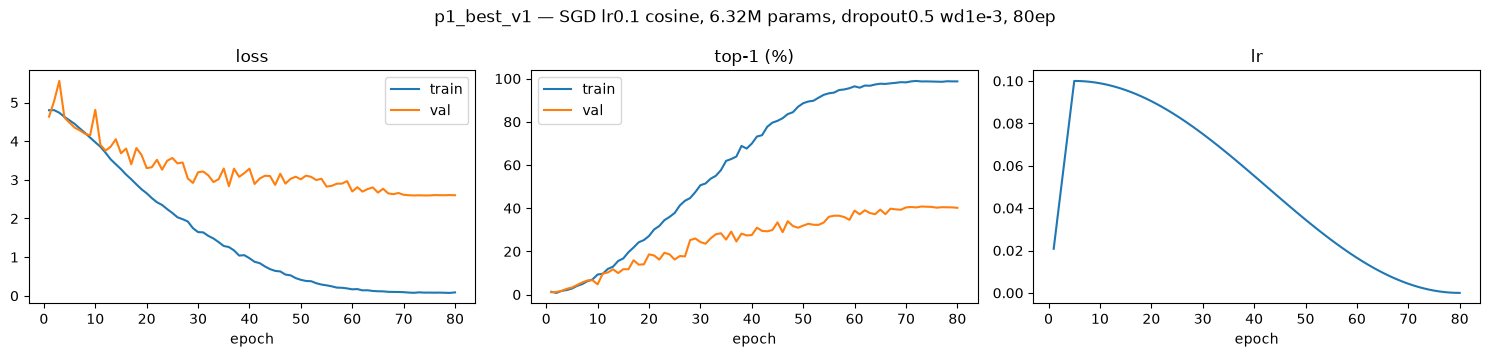

In [22]:
plot_history("p1_best_v1", title="p1_best_v1 — SGD lr0.1 cosine, 6.32M params, dropout0.5 wd1e-3, 80ep")

#### p1_best_v1 analysis

| | test top1 | test top5 | best val | params | time |
|---|---|---|---|---|---|
| p1_baseline | 34.32% | 63.85% | 34.29% | 11.2M | 38.0 min |
| **p1_best_v1** | **40.74%** | **70.96%** | 40.77% | 6.32M | 37.3 min |
| gain | **+6.42** | **+7.11** | +6.48 | halved | about the same |

- **Half the parameters, yet clearly better**: matching the capacity to the data size and regularising harder (dropout 0.5, wd 1e-3) is more effective than simply adding parameters. (On this cluster the wall-clock time is about the same as for the baseline, which suggests that the runs here are limited by data loading rather than by the model size; we did not profile this.)
- **The "annealing tail bonus" is visible**: the largest gains come while the cosine schedule decays the LR: val is 31.9% at epoch 50, 36.5% at epoch 57 and 40.4% at epoch 70, after which it plateaus (40.2% at epoch 80) as the LR approaches 0. The baseline also stabilises late, but at a much lower level.
- **The overfitting gap narrows but does not disappear**: the train/val gap goes from 65.5 (baseline) to **58.5** (final train 98.7% vs val 40.2%) — healthier than the baseline, but still the dominant effect.
- The last five epochs (40.2, 40.5, 40.4, 40.4, 40.2%) are on a plateau, so simply adding epochs has little to offer.
- About 9.3 points are still missing to the ≈50% reference. Next we add `label_smoothing=0.1` (a cheap, classic regulariser) and check whether it gets closer.

#### Why try label smoothing

Argument from lecture P2L6: the cross-entropy loss is never "satisfied". The softmax ratio `correct / (correct + others)` only equals 1 (loss = 0) if the correct logit goes to +∞ or all the other logits go to −∞. Since a network can never reach infinity, the loss keeps pushing the correct logit up and the others down even for samples that are already classified correctly — one of the mechanisms that drive the training accuracy to 99% while val stalls (the overfitting gap of `p1_best_v1`).

**Label smoothing** (introduced in the Inception paper) replaces the one-hot target by a softened one: a mass ε is spread uniformly over *all* C classes and the remaining `1-ε` is put on the correct class, so the correct class gets `1-ε+ε/C` and every other class `ε/C`. The target is then finite, the loss is "satisfied" at finite logits and no longer pushes the weights to extremes — another form of regularisation. PyTorch ≥ 1.10 supports it natively through `nn.CrossEntropyLoss(label_smoothing=...)`; the lecture suggests values of **10%–15%**, we use `0.1`.

In [23]:
# --- p1_best candidate v2: same capacity + regularisation, plus label smoothing ---
run_experiment(
    "p1_best_v2",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384), dropout=0.5),
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3, label_smoothing=0.1),
)

=== p1_best_v2 === 6.32M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.802/  1.3% | val 4.634/  1.1% (top5  5.7%) | 27.6s


ep   2/80 | lr 0.0406 | train 4.796/  1.1% | val 5.117/  1.3% (top5  6.4%) | 27.9s


ep   3/80 | lr 0.0604 | train 4.722/  1.5% | val 4.657/  2.2% (top5  9.2%) | 27.3s


ep   4/80 | lr 0.0802 | train 4.607/  1.8% | val 4.492/  2.8% (top5 11.2%) | 27.8s


...

ep  78/80 | lr 0.0002 | train 0.973/ 99.4% | val 2.769/ 41.6% (top5 71.9%) | 27.7s


ep  79/80 | lr 0.0000 | train 0.974/ 99.2% | val 2.774/ 41.3% (top5 71.9%) | 27.6s


ep  80/80 | lr 0.0000 | train 0.986/ 99.0% | val 2.767/ 41.7% (top5 72.2%) | 27.5s


[p1_best_v2]  test top1 41.82%  top5 70.63%  |  best val 41.79%  |  37.3 min


{'name': 'p1_best_v2',
 'test_top1': 41.824182418241826,
 'test_top5': 70.62706270627062,
 'best_val_top1': 41.79417941794179,
 'n_params': 6317348,
 'minutes': 37.291552750269574,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.0634459910307633

In [24]:
results_table()

,test_top1,test_top5,val_top1,params_M,min
experiment,,,,,
p1_baseline,34.32,63.85,34.29,11.20,38.0
p1_probe_smallcap,30.51,62.02,30.42,6.32,16.5
p1_probe_smallcap_reg,30.66,64.93,30.63,6.32,16.4
p1_probe_adamw,18.27,41.31,18.30,11.20,16.5
p1_best_v1,40.74,70.96,40.77,6.32,37.3
p1_best_v2,41.82,70.63,41.79,6.32,37.3


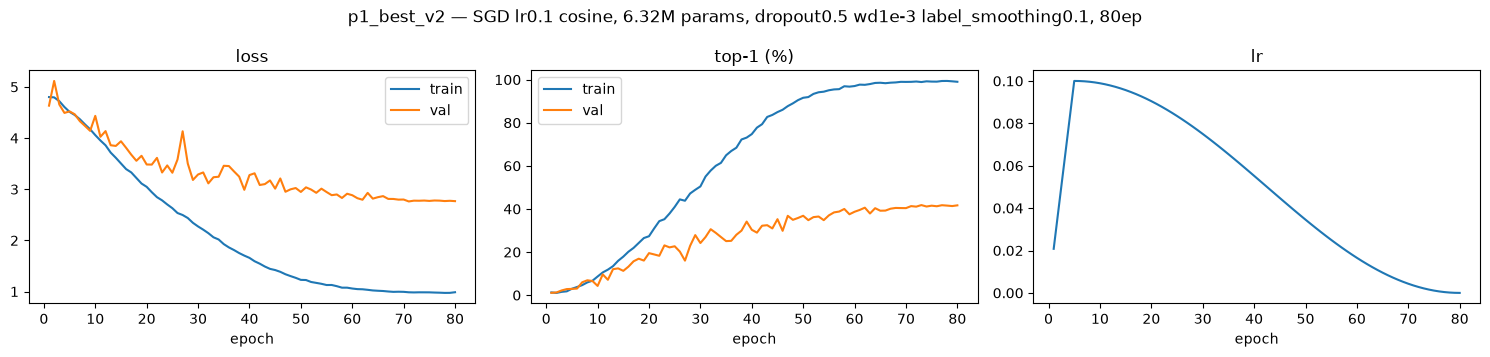

In [25]:
plot_history("p1_best_v2", title="p1_best_v2 — SGD lr0.1 cosine, 6.32M params, dropout0.5 wd1e-3 label_smoothing0.1, 80ep")

#### p1_best_v2 analysis

| | test top1 | test top5 | val top1 | final train top1 |
|---|---|---|---|---|
| p1_best_v1 (no label smoothing) | 40.74% | 70.96% | 40.77% | 98.7% |
| p1_best_v2 (label_smoothing=0.1) | 41.82% | 70.63% | 41.79% | 99.0% |
| difference | +1.08 | -0.33 | +1.02 | +0.30 |

- **No reliable effect**: in this execution label smoothing gives +1.08 points of test top-1 and -0.33 of top-5. In an earlier execution of the same notebook on Kaggle the sign was the opposite (-1.47 points of top-1 relative to the 42.36% obtained there). Differences of this size are within the run-to-run spread of the same configuration (see the reproducibility note in the ablation section), so **we cannot claim that label smoothing helps or hurts our from-scratch CNN**.
- **It does not reduce the memorisation**: the final train top-1 is almost identical (98.7% vs 99.0%) and the train/val gap is 58.5 vs 57.3. A plausible reason is that label smoothing only changes the shape of the target distribution (the correct-class target goes from 1 to 0.9), whereas top-1 accuracy only looks at the argmax; it does not limit what the network can memorise, unlike reducing the capacity or adding dropout.
- **Decision**: label smoothing is not adopted in Part 1. The reference configuration `p1_best` stays `p1_best_v1` (test top-1 40.74% / top-5 70.96%, 6.32M parameters), which is also the configuration all ablations are built on. This was a reasonable hypothesis test based on lecture P2L6 whose outcome is inconclusive, and it is reported as such.

### 1.4  Ablation study

Starting from `p1_best` (`p1_best_v1`: capacity 6.32M, dropout 0.5, wd 1e-3, 80 epochs), **one design choice is flipped at a time** and everything else is kept fixed, to show the contribution of each component:

| Ablation | Change | Expectation |
|---|---|---|
| `p1_abl_no_bn` | `use_bn=False` | lr=0.1 was tuned with BN; without it training may become unstable or diverge |
| `p1_abl_no_residual` | `use_residual=False` | slower convergence, harder to train |
| `p1_abl_no_dropout` | `dropout=0.0` | the train/val gap grows again |
| `p1_abl_flatten_head` | `global_pool="flatten"` | classification head grows from 3.85×10⁴ to 6.145×10⁵ parameters (384 channels × 4 × 4), more overfitting |
| `p1_abl_no_augment` | `augment=False` | no data augmentation, more overfitting |
| `p1_abl_no_schedule` | `scheduler="constant"` | no cosine annealing, no "tail bonus", lower and noisier accuracy |

All runs use exactly the same 80-epoch budget as `p1_best`, so the comparison is fair.

In [26]:
# --- Ablation 1: remove BatchNorm ---
run_experiment(
    "p1_abl_no_bn",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384), dropout=0.5, use_bn=False),
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3),
)

=== p1_abl_no_bn === 6.31M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.693/  1.1% | val 4.606/  1.4% (top5  5.5%) | 27.9s


ep   2/80 | lr 0.0406 | train 4.610/  1.0% | val 4.603/  1.0% (top5  5.4%) | 27.5s


ep   3/80 | lr 0.0604 | train 4.603/  1.1% | val 4.590/  1.0% (top5  5.2%) | 27.7s


ep   4/80 | lr 0.0802 | train 4.594/  1.1% | val 4.584/  1.7% (top5  7.2%) | 28.6s


...

ep  78/80 | lr 0.0002 | train 0.749/ 78.7% | val 4.523/ 25.1% (top5 54.7%) | 30.5s


ep  79/80 | lr 0.0000 | train 0.730/ 78.8% | val 4.513/ 25.4% (top5 54.8%) | 30.7s


ep  80/80 | lr 0.0000 | train 0.701/ 79.2% | val 4.518/ 25.3% (top5 54.9%) | 30.5s


[p1_abl_no_bn]  test top1 24.51%  top5 53.74%  |  best val 25.35%  |  38.2 min


{'name': 'p1_abl_no_bn',
 'test_top1': 24.512451245124513,
 'test_top5': 53.73537353735374,
 'best_val_top1': 25.352535253525353,
 'n_params': 6313716,
 'minutes': 38.18380070130031,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.06344599103076

In [27]:
# --- Ablation 2: remove residual connections ---
run_experiment(
    "p1_abl_no_residual",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384), dropout=0.5, use_residual=False),
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3),
)

=== p1_abl_no_residual === 6.22M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.668/  1.0% | val 4.610/  1.0% (top5  5.1%) | 31.1s


ep   2/80 | lr 0.0406 | train 4.623/  1.0% | val 6.798/  1.0% (top5  5.2%) | 30.9s


ep   3/80 | lr 0.0604 | train 4.619/  1.5% | val 4.637/  1.7% (top5  7.3%) | 30.9s


ep   4/80 | lr 0.0802 | train 4.592/  2.0% | val 4.513/  2.2% (top5 10.0%) | 31.0s


...

ep  78/80 | lr 0.0002 | train 0.155/ 96.9% | val 2.742/ 37.7% (top5 72.6%) | 32.3s


ep  79/80 | lr 0.0000 | train 0.140/ 97.3% | val 2.761/ 37.7% (top5 72.5%) | 31.1s


ep  80/80 | lr 0.0000 | train 0.155/ 96.8% | val 2.748/ 37.7% (top5 72.6%) | 30.1s


[p1_abl_no_residual]  test top1 39.51%  top5 72.07%  |  best val 38.04%  |  41.5 min


{'name': 'p1_abl_no_residual',
 'test_top1': 39.513951395139514,
 'test_top5': 72.06720672067206,
 'best_val_top1': 38.04380438043805,
 'n_params': 6217604,
 'minutes': 41.534177339077,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.06344599103

In [28]:
# --- Ablation 3: remove dropout ---
run_experiment(
    "p1_abl_no_dropout",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384), dropout=0.0),
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3),
)

=== p1_abl_no_dropout === 6.32M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.695/  0.8% | val 4.634/  0.9% (top5  5.9%) | 30.9s


ep   2/80 | lr 0.0406 | train 4.680/  1.3% | val 4.837/  1.1% (top5  7.4%) | 31.5s


ep   3/80 | lr 0.0604 | train 4.600/  2.3% | val 4.909/  2.0% (top5  8.4%) | 30.6s


ep   4/80 | lr 0.0802 | train 4.466/  3.7% | val 4.840/  3.5% (top5 12.6%) | 30.6s


...

ep  78/80 | lr 0.0002 | train 0.031/ 99.8% | val 2.943/ 35.6% (top5 66.3%) | 27.1s


ep  79/80 | lr 0.0000 | train 0.029/ 99.8% | val 2.948/ 35.6% (top5 66.1%) | 27.3s


ep  80/80 | lr 0.0000 | train 0.040/ 99.4% | val 2.942/ 35.5% (top5 66.2%) | 27.4s


[p1_abl_no_dropout]  test top1 35.70%  top5 65.53%  |  best val 35.82%  |  40.0 min


{'name': 'p1_abl_no_dropout',
 'test_top1': 35.7035703570357,
 'test_top5': 65.52655265526553,
 'best_val_top1': 35.823582358235825,
 'n_params': 6317348,
 'minutes': 39.95141767263412,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.06344599103

In [29]:
# --- Ablation 4: replace GAP by flatten ---
run_experiment(
    "p1_abl_flatten_head",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384), dropout=0.5, global_pool="flatten"),
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3),
)

=== p1_abl_flatten_head === 6.89M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 5.100/  1.3% | val 4.661/  1.4% (top5  6.5%) | 29.0s


ep   2/80 | lr 0.0406 | train 8.411/  1.2% | val 247.487/  1.2% (top5  5.1%) | 27.4s


ep   3/80 | lr 0.0604 | train 5.261/  0.8% | val 5.369/  1.5% (top5  6.1%) | 27.5s


ep   4/80 | lr 0.0802 | train 4.673/  1.0% | val 4.613/  1.2% (top5  5.4%) | 27.6s


...

ep  78/80 | lr 0.0002 | train 0.155/ 96.3% | val 5.182/ 18.3% (top5 41.3%) | 27.4s


ep  79/80 | lr 0.0000 | train 0.182/ 95.6% | val 5.178/ 18.2% (top5 41.2%) | 28.0s


ep  80/80 | lr 0.0000 | train 0.180/ 95.8% | val 5.181/ 18.3% (top5 41.2%) | 27.5s


[p1_abl_flatten_head]  test top1 17.52%  top5 40.77%  |  best val 18.36%  |  37.2 min


{'name': 'p1_abl_flatten_head',
 'test_top1': 17.52175217521752,
 'test_top5': 40.774077407740776,
 'best_val_top1': 18.36183618361836,
 'n_params': 6893348,
 'minutes': 37.15045711596807,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.06344599

In [30]:
# --- Ablation 5: remove data augmentation ---
run_experiment(
    "p1_abl_no_augment",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384), dropout=0.5),
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3, augment=False),
)

=== p1_abl_no_augment === 6.32M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.799/  1.3% | val 4.635/  1.1% (top5  5.3%) | 27.9s


ep   2/80 | lr 0.0406 | train 4.776/  1.4% | val 5.035/  1.6% (top5  6.6%) | 27.0s


ep   3/80 | lr 0.0604 | train 4.650/  2.5% | val 4.840/  3.0% (top5 10.2%) | 27.0s


ep   4/80 | lr 0.0802 | train 4.420/  4.5% | val 4.405/  4.1% (top5 16.4%) | 27.9s


...

ep  78/80 | lr 0.0002 | train 0.014/100.0% | val 3.468/ 20.7% (top5 45.7%) | 27.1s


ep  79/80 | lr 0.0000 | train 0.015/100.0% | val 3.470/ 20.7% (top5 45.4%) | 27.1s


ep  80/80 | lr 0.0000 | train 0.015/100.0% | val 3.470/ 20.5% (top5 45.5%) | 27.0s


[p1_abl_no_augment]  test top1 22.95%  top5 46.41%  |  best val 21.66%  |  36.7 min


{'name': 'p1_abl_no_augment',
 'test_top1': 22.952295229522953,
 'test_top5': 46.41464146414641,
 'best_val_top1': 21.662166216621664,
 'n_params': 6317348,
 'minutes': 36.68209039767583,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.063445991

In [31]:
# --- Ablation 6: remove the LR schedule (flat learning rate) ---
run_experiment(
    "p1_abl_no_schedule",
    net_cfg=NetConfig(stage_channels=(48, 96, 192, 384), dropout=0.5),
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3, scheduler="constant"),
)

=== p1_abl_no_schedule === 6.32M params | img 128 | sgd lr0.1 wd0.001 | sched=constant | 80 ep


ep   1/80 | lr 0.1000 | train 4.916/  1.3% | val 57.666/  0.9% (top5  5.0%) | 28.0s


ep   2/80 | lr 0.1000 | train 4.704/  1.8% | val 4.532/  3.0% (top5  9.6%) | 27.9s


ep   3/80 | lr 0.1000 | train 4.535/  2.5% | val 4.447/  3.2% (top5 11.6%) | 27.7s


ep   4/80 | lr 0.1000 | train 4.436/  3.2% | val 4.390/  4.2% (top5 14.8%) | 28.7s


...

ep  78/80 | lr 0.1000 | train 0.575/ 83.0% | val 3.381/ 28.6% (top5 59.9%) | 27.2s


ep  79/80 | lr 0.1000 | train 0.549/ 83.9% | val 3.564/ 29.1% (top5 59.6%) | 27.3s


ep  80/80 | lr 0.1000 | train 0.573/ 83.6% | val 3.399/ 29.5% (top5 61.1%) | 27.2s


[p1_abl_no_schedule]  test top1 31.20%  top5 65.26%  |  best val 31.86%  |  37.1 min


{'name': 'p1_abl_no_schedule',
 'test_top1': 31.203120312031203,
 'test_top5': 65.25652565256526,
 'best_val_top1': 31.863186318631865,
 'n_params': 6317348,
 'minutes': 37.140704333782196,
 'history': {'lr': [0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1,
   0.1],
  'train_loss': [4.9159261263333836,
   4.704334222353422,
   4.535458693137536,
   4.436085866047786,
   4.349131950965295,
   4.254172086715698,
   4.

,test_top1,test_top5,val_top1,params_M,min
experiment,,,,,
p1_best_v1,40.74,70.96,40.77,6.32,37.3
p1_abl_no_bn,24.51,53.74,25.35,6.31,38.2
p1_abl_no_residual,39.51,72.07,38.04,6.22,41.5
p1_abl_no_dropout,35.70,65.53,35.82,6.32,40.0
p1_abl_flatten_head,17.52,40.77,18.36,6.89,37.2
p1_abl_no_augment,22.95,46.41,21.66,6.32,36.7
p1_abl_no_schedule,31.20,65.26,31.86,6.32,37.1


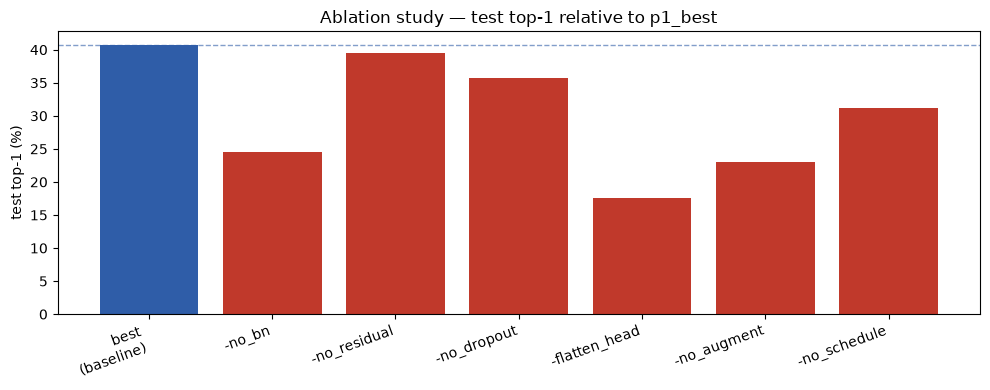

In [32]:
ABLATION_NAMES = ["p1_best_v1", "p1_abl_no_bn", "p1_abl_no_residual", "p1_abl_no_dropout",
                  "p1_abl_flatten_head", "p1_abl_no_augment", "p1_abl_no_schedule"]
tbl = results_table(ABLATION_NAMES)
display(tbl)

fig, ax = plt.subplots(figsize=(10, 4))
vals = [RESULTS[n]["test_top1"] for n in ABLATION_NAMES]
colors_ = ["#2f5da8"] + ["#c0392b"] * (len(ABLATION_NAMES) - 1)
ax.bar(range(len(ABLATION_NAMES)), vals, color=colors_)
ax.set_xticks(range(len(ABLATION_NAMES)))
ax.set_xticklabels(["best\n(baseline)"] + [n.replace("p1_abl_", "-") for n in ABLATION_NAMES[1:]],
                   rotation=20, ha="right")
ax.set_ylabel("test top-1 (%)")
ax.axhline(vals[0], color="#2f5da8", linestyle="--", linewidth=1, alpha=0.6)
ax.set_title("Ablation study — test top-1 relative to p1_best")
plt.tight_layout(); plt.show()

#### Ablation results

**Reproducibility note**: GPU training is not bit-wise reproducible even with a fixed seed (`cudnn.benchmark=True`, AMP float16 reductions that are not associative, different library versions). Every experiment was run twice on different machines: first on Kaggle (T4, over several sessions), then in one single pass of this whole notebook on the university cluster (RTX 2080 Ti, PyTorch 2.11); the outputs in this notebook are those of the cluster run. For 14 of the 15 experiments that exist in both executions the test top-1 differs by less than 2 points; the largest difference is 3.9 points for the unstable `p1_abl_no_bn` run. **Differences of 1–2 points between configurations should therefore not be interpreted.** All drops below are computed against the `p1_best_v1` run of the same execution (40.74%).

| Ablation | test top1 | drop vs best |
|---|---|---|
| p1_best_v1 (reference) | 40.74% | — |
| `p1_abl_flatten_head` | 17.52% | -23.22 |
| `p1_abl_no_augment` | 22.95% | -17.79 |
| `p1_abl_no_bn` | 24.51% | -16.23 |
| `p1_abl_no_schedule` | 31.20% | -9.54 |
| `p1_abl_no_dropout` | 35.70% | -5.04 |
| `p1_abl_no_residual` | 39.51% | -1.23 |

**Mechanism behind each result**

- **GAP → flatten (-23.22, the largest drop)**: not the expected "classical overfitting" pattern — the final train top-1 is lower than for `p1_best` (95.8% vs 98.7%). The log shows a severe instability at epoch 2 (train loss 8.4, val loss 247), which indicates that "6144-dim flatten + dropout 0.5" is simply **hard to optimise**, not only that it has too much capacity.
- **No augmentation (-17.79)**: the train top-1 reaches 100% at epoch 24; once the model has memorised all the training images nothing new can be learned. Val stays between 20.5% and 21.7% from epoch 30 on and the **annealing tail bonus never appears** (unlike `p1_best`, which improves clearly in the second half of training).
- **No BN (-16.23)**: not a divergence, but a much slower convergence — after 80 epochs the train top-1 is only 79.2% (98.7% for `p1_best`). BN's main value is that it lets the optimisation converge much faster within a limited budget; without it the network is heavily under-trained.
- **No LR schedule (-9.54)**: with lr=0.1 throughout, the final train top-1 is only 83.6% and val is still oscillating in the last 12 epochs (between 25.2% and 30.8%), with no steady rise at the end as in `p1_best`. This supports the "annealing tail bonus" explanation: without the decay, the final-phase stabilisation does not happen.
- **No dropout (-5.04)**: as expected, the final train top-1 is higher than for `p1_best` (99.4% vs 98.7%) and overfitting gets worse (gap 63.9 vs 58.5); this is the mildest of the five clear drops.
- **No residual connections (-1.23)**: practically no effect given the run-to-run spread. The network only has 8 convolutional layers (4 stages × 2 blocks), and at this depth the "easier to train" advantage of residual connections is not clearly visible (it usually appears in networks with dozens of layers). There are hints of slightly harder optimisation without them (a val-loss spike of 6.8 in the first epochs, final train top-1 96.8% vs 98.7%), but not enough to conclude. In a shallow network residual connections mainly seem to contribute optimisation stability rather than final accuracy.

**Overall conclusion**: **GAP, data augmentation and BatchNorm** are decisive (drops of 16–23 points), the **LR schedule** comes next (≈10 points), **dropout** gives a milder but real regularisation benefit (5.0 points), and **residual connections** at this depth have no effect we can separate from run-to-run noise. This closes Part 1.

## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `FGVCAircraft`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~70%.

### 2.0  Design notes

- **Normalisation**: 2A and 2B both use the **ImageNet mean/std**. The pretrained weights were learned under ImageNet normalisation, and using FGVC statistics would distort the pretrained features. Normalisation is a precondition for using a pretrained model rather than a "training hyper-parameter", so it does not break the "2A uses exactly the same hyper-parameters as the Part 1 best model" comparison.
- **Fine-tuning strategy**: all layers are trained (the backbone is not frozen), which is the literal reading of "fine-tune". The assignment text does not say whether the backbone has to be frozen, so this is our own interpretation (as opposed to feature extraction / linear probing, where only a new head is trained).
- **`run_experiment` extension**: the new `model_builder` argument bypasses our own `build_model(net_cfg)` and trains an externally built ResNet-18; the rest of the framework (`train_loop`, `evaluate`, result logging, checkpoints) is reused unchanged from Part 1.

In [33]:
def build_resnet18(num_classes=100, pretrained=True, freeze_backbone=False):
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = torchvision.models.resnet18(weights=weights)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad_(False)
    model.fc = nn.Linear(model.fc.in_features, num_classes)  # the new head is always trainable
    return model

_m = build_resnet18()
print(f"resnet18 params: {sum(p.numel() for p in _m.parameters())/1e6:.2f}M "
      f"(trainable: {sum(p.numel() for p in _m.parameters() if p.requires_grad)/1e6:.2f}M)")
del _m

resnet18 params: 11.23M (trainable: 11.23M)


### 2.1  Part 2A — fine-tuning with exactly the training hyper-parameters of the Part 1 best model

The hyper-parameters are copied from `p1_best`: SGD lr 0.1 with 5-epoch warm-up + cosine, wd 1e-3, batch 128, 80 epochs, 128 px and the same data augmentation. The only differences are that the model is the pretrained ResNet-18 and the normalisation is the ImageNet mean/std.

In [34]:
run_experiment(
    "p2a_resnet18",
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3, img_size=128,
                          mean=IMAGENET_MEAN, std=IMAGENET_STD),
    model_builder=lambda: build_resnet18(num_classes=NUM_CLASSES),
)

=== p2a_resnet18 === 11.23M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.793/  1.1% | val 4.679/  1.8% (top5  7.6%) | 28.3s


ep   2/80 | lr 0.0406 | train 3.811/ 14.2% | val 4.030/ 16.0% (top5 36.9%) | 27.7s


ep   3/80 | lr 0.0604 | train 2.447/ 34.0% | val 3.323/ 20.5% (top5 50.3%) | 27.9s


ep   4/80 | lr 0.0802 | train 2.317/ 37.4% | val 4.572/ 17.7% (top5 43.9%) | 28.0s


...

ep  78/80 | lr 0.0002 | train 0.013/100.0% | val 1.672/ 56.7% (top5 83.3%) | 27.6s


ep  79/80 | lr 0.0000 | train 0.012/100.0% | val 1.669/ 56.5% (top5 83.2%) | 27.3s


ep  80/80 | lr 0.0000 | train 0.012/100.0% | val 1.668/ 56.9% (top5 83.3%) | 27.4s


[p2a_resnet18]  test top1 57.70%  top5 83.56%  |  best val 56.95%  |  37.1 min


{'name': 'p2a_resnet18',
 'test_top1': 57.695769576957694,
 'test_top5': 83.55835583558355,
 'best_val_top1': 56.94569456945695,
 'n_params': 11227812,
 'minutes': 37.10394065777461,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.06344599103076

In [35]:
results_table()

,test_top1,test_top5,val_top1,params_M,min
experiment,,,,,
p1_baseline,34.32,63.85,34.29,11.20,38.0
p1_probe_smallcap,30.51,62.02,30.42,6.32,16.5
p1_probe_smallcap_reg,30.66,64.93,30.63,6.32,16.4
p1_probe_adamw,18.27,41.31,18.30,11.20,16.5
p1_best_v1,40.74,70.96,40.77,6.32,37.3
p1_best_v2,41.82,70.63,41.79,6.32,37.3
p1_abl_no_bn,24.51,53.74,25.35,6.31,38.2
p1_abl_no_residual,39.51,72.07,38.04,6.22,41.5
p1_abl_no_dropout,35.70,65.53,35.82,6.32,40.0


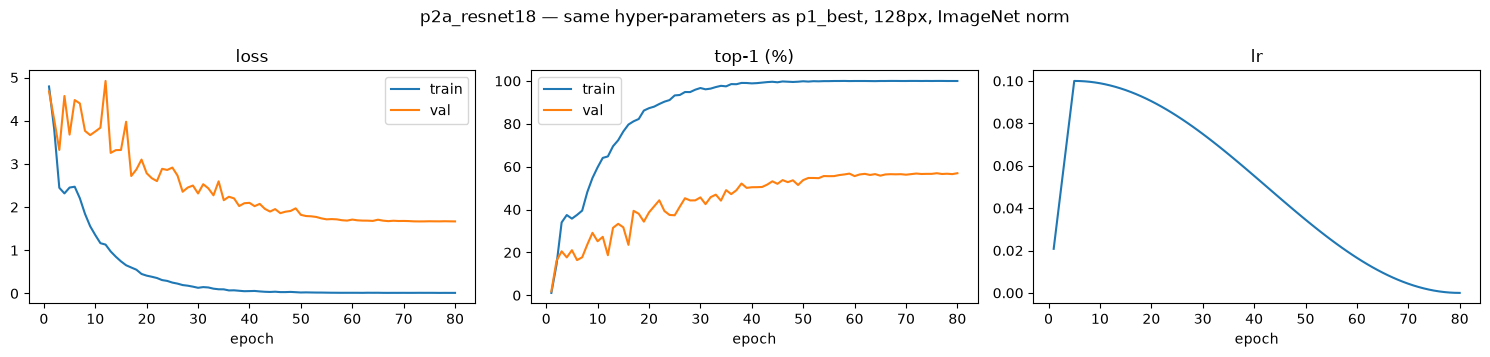

In [36]:
plot_history("p2a_resnet18", title="p2a_resnet18 — same hyper-parameters as p1_best, 128px, ImageNet norm")

#### p2a_resnet18 analysis

| | test top1 | test top5 | best val | params | time |
|---|---|---|---|---|---|
| p1_best_v1 (same execution) | 40.74% | 70.96% | 40.77% | 6.32M | 37.3 min |
| **p2a_resnet18** | **57.70%** | **83.56%** | 56.95% | 11.23M | 37.1 min |
| gain | **+16.95** | **+12.60** | +16.17 | — | similar |

- **With exactly the same training hyper-parameters, simply switching to ImageNet-pretrained weights adds about 17 points** — the cleanest comparison so far; it shows the value of the pretrained features, independently of any tuning.
- **Non-monotonic validation accuracy early in training**: during the high-LR phase val top-1 goes 1.8, 16.0, 20.5, 17.7, 21.0, 16.4, 17.7, 23.7% over the first 8 epochs, i.e. it falls back from 20.5% (epoch 3) to 16.4% (epoch 6) before recovering (an earlier Kaggle execution showed a deeper dip, 25% → 12%). A possible reason: the peak learning rate 0.1 was tuned for training from scratch and may be too large for a network that starts from good pretrained weights. This is a further direction for 2B besides the three planned changes; we first run 2B as planned.
- **Less overfitting than the from-scratch network**: the train top-1 reaches 99.5% at epoch 44 and val ends at 56.9%, a gap of 43.0 points versus 58.5 for `p1_best_v1` — pretrained features overfit less by nature.
- The "annealing tail bonus" is again visible: val is 51.6% at epoch 43, 53.7% at epoch 50 and 56.9% at epoch 80.

### 2.2  Part 2B — tuning towards ~70% (justified with the P2L6 lecture)

Lecture 24 (P2L6, *Regularization and Training Recipes*) presents the training recipe PyTorch/torchvision used in 2021 to re-train its pretrained weights (citing Karpathy's blog post *A Recipe for Training Neural Networks* and the official torchvision blog). We apply the ingredients that are most relevant to us:

- **Resolution matched to the pretraining scale**: ResNet-18 was pretrained at 224 px, so running it at 128 px (2A) feeds it inputs that are much smaller than what it is used to. 2B uses 224 px for train, val and test. *Note*: the "FixRes effect" mentioned in the lecture refers to deliberately using different train and test resolutions (e.g. train at 128, test at 224), which is a different and finer trick. We do **not** implement a train/test resolution mismatch; we simply use 224 px everywhere to match the pretraining resolution, so we do not cite FixRes for this choice.
- **No weight decay on BatchNorm parameters**: the torchvision team found that weight decay on the BN γ/β does not help ("batch norm is weird"). This is the new `no_wd_on_bn=True` switch (1-D parameters — the BN parameters and all biases — get no weight decay).
- **Training longer only pays off once augmentation is in place**: we already have augmentation, so a longer schedule would be a reasonable follow-up.
- **Label smoothing**: part of the combined recipe in the lecture. It had no measurable effect on our from-scratch CNN (within the run-to-run noise), but ResNet-18 at 224 px is a different regime, so it is worth testing again.

**2B configuration**: 224 px (train/val/test) + ImageNet norm + `no_wd_on_bn=True` + `label_smoothing=0.1`; the number of epochs stays at 80 (we first look at the effect of these changes without also increasing the epoch budget, to avoid changing too many variables at once).

In [37]:
run_experiment(
    "p2b_resnet18_tuned",
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3, img_size=224,
                          mean=IMAGENET_MEAN, std=IMAGENET_STD,
                          no_wd_on_bn=True, label_smoothing=0.1),
    model_builder=lambda: build_resnet18(num_classes=NUM_CLASSES),
)

=== p2b_resnet18_tuned === 11.23M params | img 224 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.727/  1.3% | val 4.641/  1.4% (top5  7.0%) | 43.2s


ep   2/80 | lr 0.0406 | train 3.969/ 14.8% | val 3.441/ 21.4% (top5 49.6%) | 32.1s


ep   3/80 | lr 0.0604 | train 2.639/ 43.4% | val 3.344/ 26.3% (top5 54.9%) | 31.4s


ep   4/80 | lr 0.0802 | train 2.068/ 60.7% | val 3.874/ 20.9% (top5 49.4%) | 32.0s


...

ep  78/80 | lr 0.0002 | train 0.797/100.0% | val 1.961/ 70.4% (top5 89.4%) | 31.7s


ep  79/80 | lr 0.0000 | train 0.797/100.0% | val 1.958/ 70.4% (top5 89.6%) | 31.8s


ep  80/80 | lr 0.0000 | train 0.797/100.0% | val 1.959/ 70.4% (top5 89.6%) | 32.1s


[p2b_resnet18_tuned]  test top1 70.57%  top5 89.62%  |  best val 70.39%  |  43.2 min


{'name': 'p2b_resnet18_tuned',
 'test_top1': 70.56705670567057,
 'test_top5': 89.61896189618962,
 'best_val_top1': 70.38703870387039,
 'n_params': 11227812,
 'minutes': 43.19963066975276,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.063445991

In [38]:
results_table(["p1_best_v1", "p2a_resnet18", "p2b_resnet18_tuned"])

,test_top1,test_top5,val_top1,params_M,min
experiment,,,,,
p1_best_v1,40.74,70.96,40.77,6.32,37.3
p2a_resnet18,57.70,83.56,56.95,11.23,37.1
p2b_resnet18_tuned,70.57,89.62,70.39,11.23,43.2


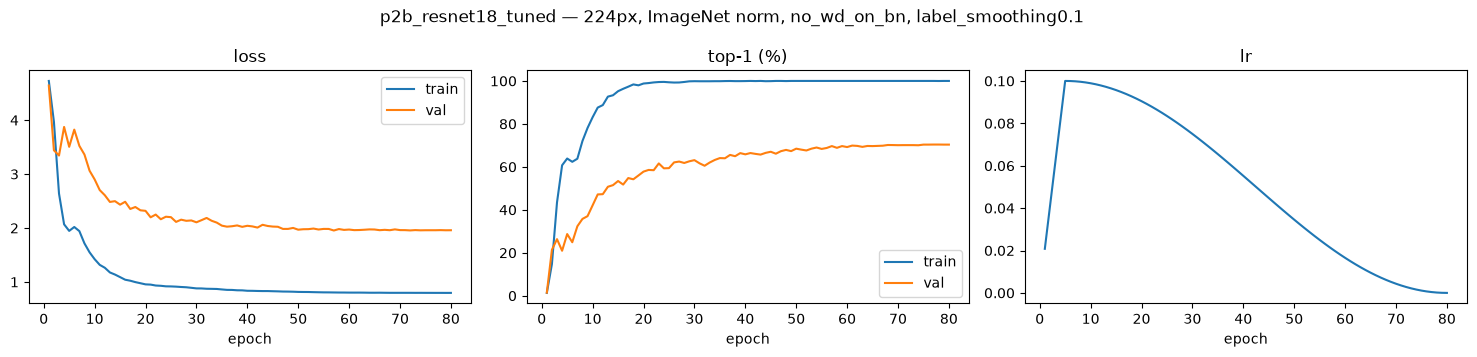

In [39]:
plot_history("p2b_resnet18_tuned", title="p2b_resnet18_tuned — 224px, ImageNet norm, no_wd_on_bn, label_smoothing0.1")

#### p2b_resnet18_tuned analysis

| | test top1 | test top5 | best val | time |
|---|---|---|---|---|
| p2a_resnet18 | 57.70% | 83.56% | 56.95% | 37.1 min |
| **p2b_resnet18_tuned** | **70.57%** | **89.62%** | 70.39% | 43.2 min |
| gain | **+12.87** | **+6.06** | +13.44 | — |

**Target reached**: test top-1 **70.57%**, just above the ~70% asked for by the assignment (the margin is smaller than the run-to-run spread; an earlier Kaggle execution gave 71.50%).

- **The three changes together add about 13 points**: 224 px (matching the pretraining resolution) + `no_wd_on_bn=True` + `label_smoothing=0.1`. The individual contributions are measured in the ablation below: they are **not** equal — resolution and label smoothing matter, the BN weight-decay exemption does not show a measurable effect.
- **The train/val gap narrows clearly**: the train top-1 reaches 99.5% at epoch 24 and val ends at 70.4%, a gap of 29.6 points versus 43.0 for 2A.
- **Label smoothing behaves as expected here**: the final `train_loss` stays at **0.797** instead of going to 0, which is the behaviour of a softened target (the loss has a non-zero floor).
- **Non-monotonic validation accuracy in the first epochs again** (val top-1 1.4, 21.4, 26.3, 20.9, 28.7, 24.9, 32.3, 35.8% over the first 8 epochs), as in 2A, which is compatible with a peak LR that is too large for a pretrained network; the final convergence is not affected.
- **The annealing tail bonus is smaller here**: val is 65.7% at epoch 43, 68.5% at epoch 50 and 70.4% at epoch 80.

**Conclusion**: Part 2 is complete — 2A (control) 57.70% → 2B (tuned) 70.57%, at the ~70% target, and every change is backed by the course material.

### 2.3  Part 2B ablation: how much does each of the three changes contribute?

Starting from `p2b_resnet18_tuned` (224 px + no_wd_on_bn + label_smoothing 0.1, test top-1 71.50%), one change at a time is removed, in the same spirit as the Part 1 ablation:

| Ablation | Change |
|---|---|
| `p2b_abl_128px` | back to 128 px (removes the resolution change) |
| `p2b_abl_wd_on_bn` | `no_wd_on_bn=False` (removes the BN weight-decay exemption) |
| `p2b_abl_no_label_smoothing` | `label_smoothing=0.0` (removes label smoothing) |

In [40]:
# --- 2B ablation 1: remove 224 px (back to 128 px) ---
run_experiment(
    "p2b_abl_128px",
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3, img_size=128,
                          mean=IMAGENET_MEAN, std=IMAGENET_STD,
                          no_wd_on_bn=True, label_smoothing=0.1),
    model_builder=lambda: build_resnet18(num_classes=NUM_CLASSES),
)

=== p2b_abl_128px === 11.23M params | img 128 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.799/  1.1% | val 4.697/  1.9% (top5  7.2%) | 27.9s


ep   2/80 | lr 0.0406 | train 4.006/ 13.0% | val 3.977/ 17.2% (top5 39.2%) | 27.9s


ep   3/80 | lr 0.0604 | train 2.914/ 34.4% | val 3.795/ 18.6% (top5 50.1%) | 27.8s


ep   4/80 | lr 0.0802 | train 2.682/ 40.8% | val 4.010/ 20.1% (top5 48.6%) | 28.4s


...

ep  78/80 | lr 0.0002 | train 0.801/100.0% | val 2.306/ 58.4% (top5 81.8%) | 27.3s


ep  79/80 | lr 0.0000 | train 0.802/100.0% | val 2.305/ 58.7% (top5 81.5%) | 27.3s


ep  80/80 | lr 0.0000 | train 0.801/100.0% | val 2.304/ 58.8% (top5 81.6%) | 28.7s


[p2b_abl_128px]  test top1 58.06%  top5 82.75%  |  best val 59.05%  |  37.4 min


{'name': 'p2b_abl_128px',
 'test_top1': 58.05580558055806,
 'test_top5': 82.74827482748275,
 'best_val_top1': 59.045904590459045,
 'n_params': 11227812,
 'minutes': 37.36645835638046,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.0634459910307

In [41]:
# --- 2B ablation 2: remove no_wd_on_bn ---
run_experiment(
    "p2b_abl_wd_on_bn",
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3, img_size=224,
                          mean=IMAGENET_MEAN, std=IMAGENET_STD,
                          no_wd_on_bn=False, label_smoothing=0.1),
    model_builder=lambda: build_resnet18(num_classes=NUM_CLASSES),
)

=== p2b_abl_wd_on_bn === 11.23M params | img 224 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.727/  1.3% | val 4.641/  1.4% (top5  7.0%) | 33.5s


ep   2/80 | lr 0.0406 | train 3.974/ 14.8% | val 3.466/ 20.6% (top5 49.0%) | 31.9s


ep   3/80 | lr 0.0604 | train 2.644/ 43.5% | val 3.328/ 26.9% (top5 56.7%) | 31.6s


ep   4/80 | lr 0.0802 | train 2.069/ 59.7% | val 3.100/ 33.1% (top5 64.7%) | 33.0s


...

ep  78/80 | lr 0.0002 | train 0.798/100.0% | val 1.938/ 69.8% (top5 90.7%) | 31.9s


ep  79/80 | lr 0.0000 | train 0.797/100.0% | val 1.935/ 70.0% (top5 90.9%) | 31.7s


ep  80/80 | lr 0.0000 | train 0.798/100.0% | val 1.936/ 70.2% (top5 90.8%) | 31.7s


[p2b_abl_wd_on_bn]  test top1 71.38%  top5 91.15%  |  best val 70.45%  |  42.9 min


{'name': 'p2b_abl_wd_on_bn',
 'test_top1': 71.37713771377138,
 'test_top5': 91.14911491149115,
 'best_val_top1': 70.44704470447044,
 'n_params': 11227812,
 'minutes': 42.917780864238736,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.0634459910

In [42]:
# --- 2B ablation 3: remove label smoothing ---
run_experiment(
    "p2b_abl_no_label_smoothing",
    train_cfg=TrainConfig(epochs=80, weight_decay=1e-3, img_size=224,
                          mean=IMAGENET_MEAN, std=IMAGENET_STD,
                          no_wd_on_bn=True, label_smoothing=0.0),
    model_builder=lambda: build_resnet18(num_classes=NUM_CLASSES),
)

=== p2b_abl_no_label_smoothing === 11.23M params | img 224 | sgd lr0.1 wd0.001 | sched=cosine | 80 ep


ep   1/80 | lr 0.0208 | train 4.723/  1.4% | val 4.628/  1.5% (top5  7.1%) | 34.5s


ep   2/80 | lr 0.0406 | train 3.789/ 15.3% | val 3.196/ 19.4% (top5 46.9%) | 32.2s


ep   3/80 | lr 0.0604 | train 2.118/ 43.1% | val 2.837/ 27.9% (top5 58.1%) | 32.7s


ep   4/80 | lr 0.0802 | train 1.500/ 56.4% | val 3.500/ 23.5% (top5 57.4%) | 34.7s


...

ep  78/80 | lr 0.0002 | train 0.003/100.0% | val 1.451/ 65.5% (top5 88.5%) | 31.6s


ep  79/80 | lr 0.0000 | train 0.003/100.0% | val 1.451/ 65.4% (top5 88.4%) | 31.8s


ep  80/80 | lr 0.0000 | train 0.003/100.0% | val 1.446/ 65.6% (top5 88.4%) | 32.0s


[p2b_abl_no_label_smoothing]  test top1 65.95%  top5 87.97%  |  best val 65.74%  |  42.9 min


{'name': 'p2b_abl_no_label_smoothing',
 'test_top1': 65.94659465946594,
 'test_top5': 87.96879687968797,
 'best_val_top1': 65.73657365736574,
 'n_params': 11227812,
 'minutes': 42.88386435111364,
 'history': {'lr': [0.0208,
   0.0406,
   0.060399999999999995,
   0.0802,
   0.1,
   0.09995614150494292,
   0.09982464296247522,
   0.0996057350657239,
   0.09929980185352524,
   0.09890738003669028,
   0.09842915805643154,
   0.09786597487660335,
   0.09721881851187406,
   0.09648882429441256,
   0.09567727288213004,
   0.09478558801197065,
   0.09381533400219319,
   0.09276821300802536,
   0.091646062035505,
   0.09045084971874741,
   0.08918467286629203,
   0.08784975278258786,
   0.08644843137107061,
   0.08498316702566831,
   0.08345653031794295,
   0.08187119948743453,
   0.0802299557431188,
   0.07853567838422164,
   0.07679133974894986,
   0.07500000000000002,
   0.07316480175599312,
   0.07128896457825366,
   0.06937577932260518,
   0.06742860236609079,
   0.0654508497187474,
   0.0

,test_top1,test_top5,val_top1,params_M,min
experiment,,,,,
p2a_resnet18,57.70,83.56,56.95,11.23,37.1
p2b_abl_128px,58.06,82.75,59.05,11.23,37.4
p2b_abl_wd_on_bn,71.38,91.15,70.45,11.23,42.9
p2b_abl_no_label_smoothing,65.95,87.97,65.74,11.23,42.9
p2b_resnet18_tuned,70.57,89.62,70.39,11.23,43.2


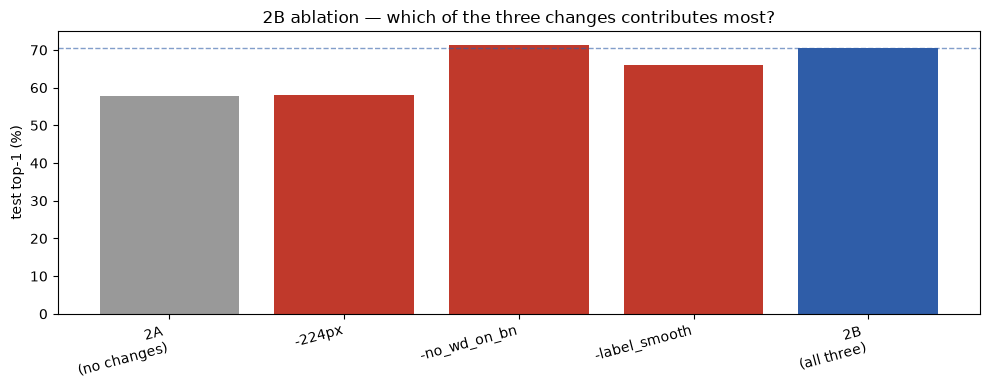

In [43]:
P2B_ABLATION_NAMES = ["p2a_resnet18", "p2b_abl_128px", "p2b_abl_wd_on_bn",
                      "p2b_abl_no_label_smoothing", "p2b_resnet18_tuned"]
tbl = results_table(P2B_ABLATION_NAMES)
display(tbl)

fig, ax = plt.subplots(figsize=(10, 4))
vals = [RESULTS[n]["test_top1"] for n in P2B_ABLATION_NAMES]
colors_ = ["#999999", "#c0392b", "#c0392b", "#c0392b", "#2f5da8"]
ax.bar(range(len(P2B_ABLATION_NAMES)), vals, color=colors_)
ax.set_xticks(range(len(P2B_ABLATION_NAMES)))
ax.set_xticklabels(["2A\n(no changes)", "-224px", "-no_wd_on_bn", "-label_smooth", "2B\n(all three)"],
                   rotation=15, ha="right")
ax.set_ylabel("test top-1 (%)")
ax.axhline(vals[-1], color="#2f5da8", linestyle="--", linewidth=1, alpha=0.6)
ax.set_title("2B ablation — which of the three changes contributes most?")
plt.tight_layout(); plt.show()

#### 2B ablation results

| Experiment | test top1 | test top5 | val top1 | final train−val gap |
|---|---|---|---|---|
| p2a_resnet18 (none of the three changes) | 57.70% | 83.56% | 56.95% | 43.0 |
| p2b_abl_128px (resolution change removed) | 58.06% | 82.75% | 59.05% | 41.2 |
| p2b_abl_wd_on_bn (BN weight-decay exemption removed) | 71.38% | 91.15% | 70.45% | 29.8 |
| p2b_abl_no_label_smoothing (label smoothing removed) | 65.95% | 87.97% | 65.74% | 34.4 |
| p2b_resnet18_tuned (all three changes) | 70.57% | 89.62% | 70.39% | 29.6 |

Drops relative to the full 2B configuration (70.57%): removing the resolution change **-12.51**, removing label smoothing **-4.62**, removing the BN weight-decay exemption **+0.81** (a *gain*, within the run-to-run spread).

- **Resolution is the dominant factor**: going back from 224 px to 128 px drops the test top-1 from 70.57% to 58.06%, i.e. most of the 13-point 2A → 2B gain, and the final gap grows from 29.6 to 41.2.
- **Label smoothing matters at 224 px**: without it the test top-1 falls to 65.95% (gap 34.4 instead of 29.6); the train top-1 also needs longer to reach 99.5% (epoch 43 vs 24).
- **No measurable benefit from excluding BN parameters from weight decay**: removing the exemption gives 71.38%, i.e. not worse. The recipe from the lecture is kept in the configuration, but we cannot claim from our data that it helps.
- **The effects are not additive**: at 128 px the two regularisation changes together add only +0.36 over 2A (within noise), while at 224 px label smoothing alone is worth 4.6 points. The three drops (-12.51, -4.62, +0.81) do not sum to the 2A → 2B gain (+12.87); the changes interact (label smoothing seems to pay off once the model works at its native resolution), which is itself worth reporting.